In [1]:
# ─── Imports ─────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120


In [2]:

best_model = joblib.load('models/best_model.pkl')
print(f'Model loaded: {type(best_model).__name__}')
print(best_model)

Model loaded: VotingClassifier
VotingClassifier(estimators=[('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.8, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=True,
                                            eval_metric='auc',
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constrai...
                                         

In [3]:

encoding_info = joblib.load('models/encoding_info.pkl')
feature_cols  = joblib.load('models/feature_columns.pkl')
scaler        = joblib.load('models/scaler.pkl')

print(f'Binary columns       : {encoding_info["binary_cols"]}')
print(f'Range anxiety map    : {encoding_info["range_anxiety_map"]}')
print(f'Nominal columns (OHE): {encoding_info["nominal_cols"]}')
print(f'Expected features ({len(feature_cols)}): {feature_cols}')

Binary columns       : ['Home_Charging_Possible', 'Subsidy_Available']
Range anxiety map    : {'Low': 0, 'Medium': 1, 'High': 2}
Nominal columns (OHE): ['Gender', 'City_Type', 'Current_Car_Type']
Expected features (20): ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level', 'Gender_Female', 'Gender_Male', 'Gender_Other', 'City_Type_Rural', 'City_Type_Suburban', 'City_Type_Urban', 'Current_Car_Type_Hatchback', 'Current_Car_Type_SUV', 'Current_Car_Type_Sedan', 'Current_Car_Type_Truck']


In [4]:
test_raw = pd.read_csv('data/test.csv')
print(f'Test shape: {test_raw.shape}')
test_raw.head()

Test shape: (286571, 14)


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level
0,668665,61,67725.0,16.9,2,7,4,4.0,Male,Suburban,Sedan,Yes,No,Low
1,668666,42,152835.0,41.9,2,9,9,4.0,Male,Urban,SUV,No,No,Low
2,668667,68,86877.0,53.3,1,10,11,4.0,Female,Urban,Sedan,No,No,Low
3,668668,39,46794.0,34.1,2,4,8,4.0,Female,Suburban,Sedan,Yes,No,Low
4,668669,55,112172.0,57.2,1,6,4,1.0,Female,Suburban,Sedan,Yes,Yes,Low


In [5]:

test_ids = test_raw['id'].copy()

# Drop ID
test = test_raw.drop(columns=['id'])
print(f'Test columns: {list(test.columns)}')
print(f'Missing values: {test.isnull().sum().sum()}')

Test columns: ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']
Missing values: 0


In [6]:

print('Test dtypes:')
print(test.dtypes)

Test dtypes:
Age                              int64
Annual_Income_USD              float64
Daily_Commute_km               float64
Number_of_Cars_Owned             int64
Charging_Stations_Near_Home      int64
Charging_Stations_Near_Work      int64
Environmental_Concern_Level    float64
Gender                          object
City_Type                       object
Current_Car_Type                object
Home_Charging_Possible          object
Subsidy_Available               object
Range_Anxiety_Level             object
dtype: object



1. **Binary Encoding:** Home_Charging_Possible, Subsidy_Availabl` → {'Yes': 1, 'No': 0}
2. **Label (Ordinal) Encoding:** Range_Anxiety_Level → {'Low': 0, 'Medium': 1, 'High': 2}
3. **One-Hot Encoding:** Gender, City_Type, Current_Car_Type → dummy columns
4. **Align columns** to match the training feature order
5. **Scaling** (if the best model requires it)

In [7]:
def transform_data(df, encoding_info, feature_cols):
    """returns
    pd.DataFrame — transformed data with columns matching training
    """
    df = df.copy()
    
    #  Binary encoding
    for col in encoding_info['binary_cols']:
        df[col] = df[col].map({'Yes': 1, 'No': 0})
    
    # : Label (ordinal) encoding
    df['Range_Anxiety_Level'] = df['Range_Anxiety_Level'].map(encoding_info['range_anxiety_map'])
    
    #  One-Hot Encoding
    df = pd.get_dummies(df, columns=encoding_info['nominal_cols'], drop_first=False)
    
    # Convert bool columns to int
    bool_cols = df.select_dtypes(include='bool').columns
    df[bool_cols] = df[bool_cols].astype(int)
    
    #  Align columns with training features
    for col in feature_cols:
        if col not in df.columns:
            df[col] = 0
    
    df = df[feature_cols]
    
    return df

print('Transformation function')

Transformation function


In [8]:

test_transformed = transform_data(test, encoding_info, feature_cols)

print(f'Transformed test shape: {test_transformed.shape}')
print(f'Columns match training: {list(test_transformed.columns) == feature_cols}')
print(f'Any nulls: {test_transformed.isnull().sum().sum()}')
test_transformed.head()

Transformed test shape: (286571, 20)
Columns match training: True
Any nulls: 0


,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Gender_Female,Gender_Male,Gender_Other,City_Type_Rural,City_Type_Suburban,City_Type_Urban,Current_Car_Type_Hatchback,Current_Car_Type_SUV,Current_Car_Type_Sedan,Current_Car_Type_Truck
0,61,67725.0,16.9,2,7,4,4.0,1,0,0,0,1,0,0,1,0,0,0,1,0
1,42,152835.0,41.9,2,9,9,4.0,0,0,0,0,1,0,0,0,1,0,1,0,0
2,68,86877.0,53.3,1,10,11,4.0,0,0,0,1,0,0,0,0,1,0,0,1,0
3,39,46794.0,34.1,2,4,8,4.0,1,0,0,1,0,0,0,1,0,0,0,1,0
4,55,112172.0,57.2,1,6,4,1.0,1,1,0,1,0,0,0,1,0,0,0,1,0


In [9]:

print(test_transformed.dtypes)

Age                              int64
Annual_Income_USD              float64
Daily_Commute_km               float64
Number_of_Cars_Owned             int64
Charging_Stations_Near_Home      int64
Charging_Stations_Near_Work      int64
Environmental_Concern_Level    float64
Home_Charging_Possible           int64
Subsidy_Available                int64
Range_Anxiety_Level              int64
Gender_Female                    int64
Gender_Male                      int64
Gender_Other                     int64
City_Type_Rural                  int64
City_Type_Suburban               int64
City_Type_Urban                  int64
Current_Car_Type_Hatchback       int64
Current_Car_Type_SUV             int64
Current_Car_Type_Sedan           int64
Current_Car_Type_Truck           int64
dtype: object


In [10]:

model_name = type(best_model).__name__
needs_scaling = model_name in ['LogisticRegression', 'KNeighborsClassifier', 'SVC']

if needs_scaling:
    print(f'Model ({model_name}) requires scaled features. Applying StandardScaler...')
    test_input = scaler.transform(test_transformed)
else:
    print(f'Model ({model_name}) does NOT require scaling. Using raw features.')
    test_input = test_transformed

Model (VotingClassifier) does NOT require scaling. Using raw features.


In [11]:

y_pred_proba = best_model.predict_proba(test_input)[:, 1]

y_pred_class = best_model.predict(test_input)

print(f'Predictions generated for {len(y_pred_proba)} samples')
print(f'Probability range: [{y_pred_proba.min():.4f}, {y_pred_proba.max():.4f}]')
print(f'Mean probability: {y_pred_proba.mean():.4f}')
print(f'\nPredicted class distribution:')
print(pd.Series(y_pred_class).value_counts().rename({0: 'No', 1: 'Yes'}))

Predictions generated for 286571 samples
Probability range: [0.0000, 0.9650]
Mean probability: 0.1749

Predicted class distribution:
No     240463
Yes     46108
Name: count, dtype: int64


In [12]:

sample_sub = pd.read_csv('data/sample_submission.csv')
print(f'Sample submission shape: {sample_sub.shape}')
sample_sub.head()

Sample submission shape: (286571, 2)


,id,Will_Buy_EV
0,668665,0.174645
1,668666,0.174645
2,668667,0.174645
3,668668,0.174645
4,668669,0.174645


In [13]:

submission = pd.DataFrame({
    'id': test_ids,
    'Will_Buy_EV': y_pred_proba  
})

submission.to_csv('submission.csv', index=False)
print(f'Submission saved to submission.csv')
print(f'Shape: {submission.shape}')
submission.head(10)

Submission saved to submission.csv
Shape: (286571, 2)


,id,Will_Buy_EV
0,668665,0.009262
1,668666,0.020920
2,668667,0.004186
3,668668,0.003272
4,668669,0.021580
5,668670,0.003670
6,668671,0.368487
7,668672,0.000146
8,668673,0.657661
9,668674,0.007072


In [14]:

assert submission.shape[0] == sample_sub.shape[0], 'Row count mismatch!'
assert list(submission.columns) == list(sample_sub.columns), 'Column mismatch!'
assert submission['Will_Buy_EV'].between(0, 1).all(), 'Probabilities out of range!'

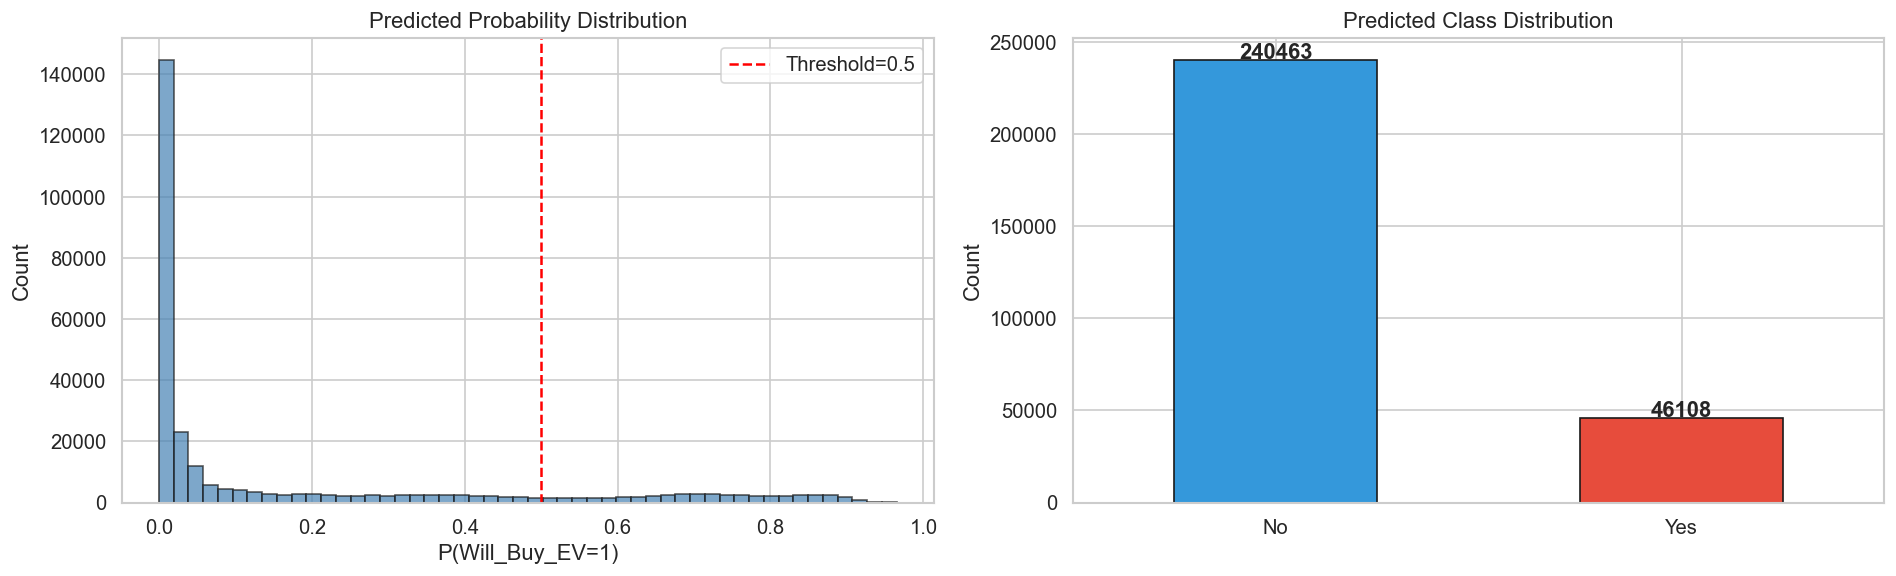

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(y_pred_proba, bins=50, edgecolor='k', alpha=0.7, color='steelblue')
axes[0].axvline(0.5, color='red', linestyle='--', label='Threshold=0.5')
axes[0].set_title('Predicted Probability Distribution')
axes[0].set_xlabel('P(Will_Buy_EV=1)')
axes[0].set_ylabel('Count')
axes[0].legend()

pred_counts = pd.Series(y_pred_class).value_counts().rename({0: 'No', 1: 'Yes'})
pred_counts.plot.bar(ax=axes[1], color=['#3498db', '#e74c3c'], edgecolor='k')
axes[1].set_title('Predicted Class Distribution')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)

for i, (idx, v) in enumerate(pred_counts.items()):
    axes[1].text(i, v + 500, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [16]:

test_analysis = test_raw.copy()
test_analysis['Predicted_Probability'] = y_pred_proba
test_analysis['Predicted_Class'] = np.where(y_pred_class == 1, 'Yes', 'No')

test_analysis.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Predicted_Probability,Predicted_Class
0,668665,61,67725.0,16.9,2,7,4,4.0,Male,Suburban,Sedan,Yes,No,Low,0.009262,No
1,668666,42,152835.0,41.9,2,9,9,4.0,Male,Urban,SUV,No,No,Low,0.020920,No
2,668667,68,86877.0,53.3,1,10,11,4.0,Female,Urban,Sedan,No,No,Low,0.004186,No
3,668668,39,46794.0,34.1,2,4,8,4.0,Female,Suburban,Sedan,Yes,No,Low,0.003272,No
4,668669,55,112172.0,57.2,1,6,4,1.0,Female,Suburban,Sedan,Yes,Yes,Low,0.021580,No


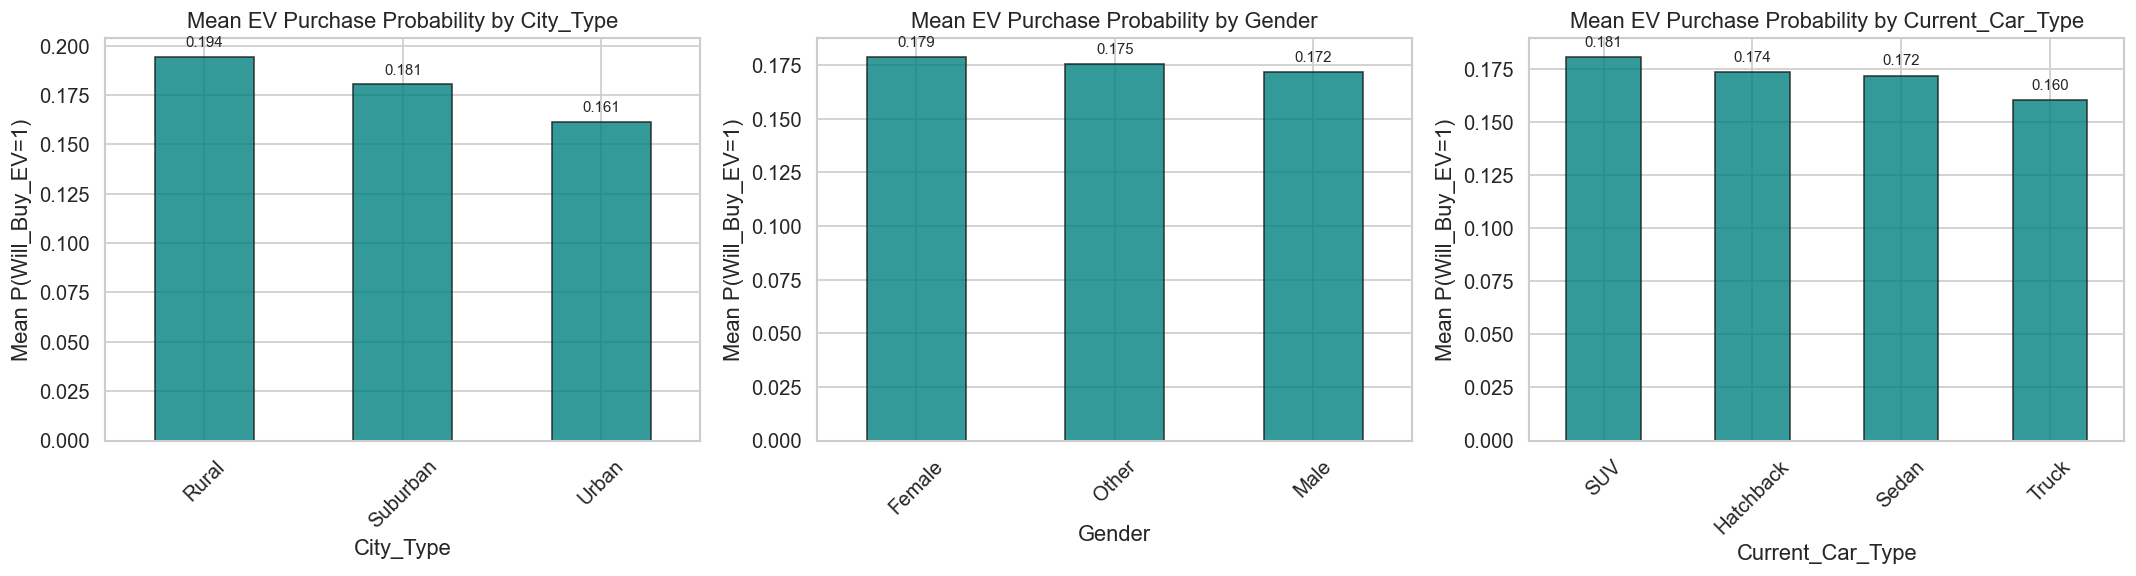

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['City_Type', 'Gender', 'Current_Car_Type']):
    group = test_analysis.groupby(col)['Predicted_Probability'].mean().sort_values(ascending=False)
    group.plot.bar(ax=axes[i], color='teal', edgecolor='k', alpha=0.8)
    axes[i].set_title(f'Mean EV Purchase Probability by {col}')
    axes[i].set_ylabel('Mean P(Will_Buy_EV=1)')
    axes[i].tick_params(axis='x', rotation=45)
    for j, (idx, v) in enumerate(group.items()):
        axes[i].text(j, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

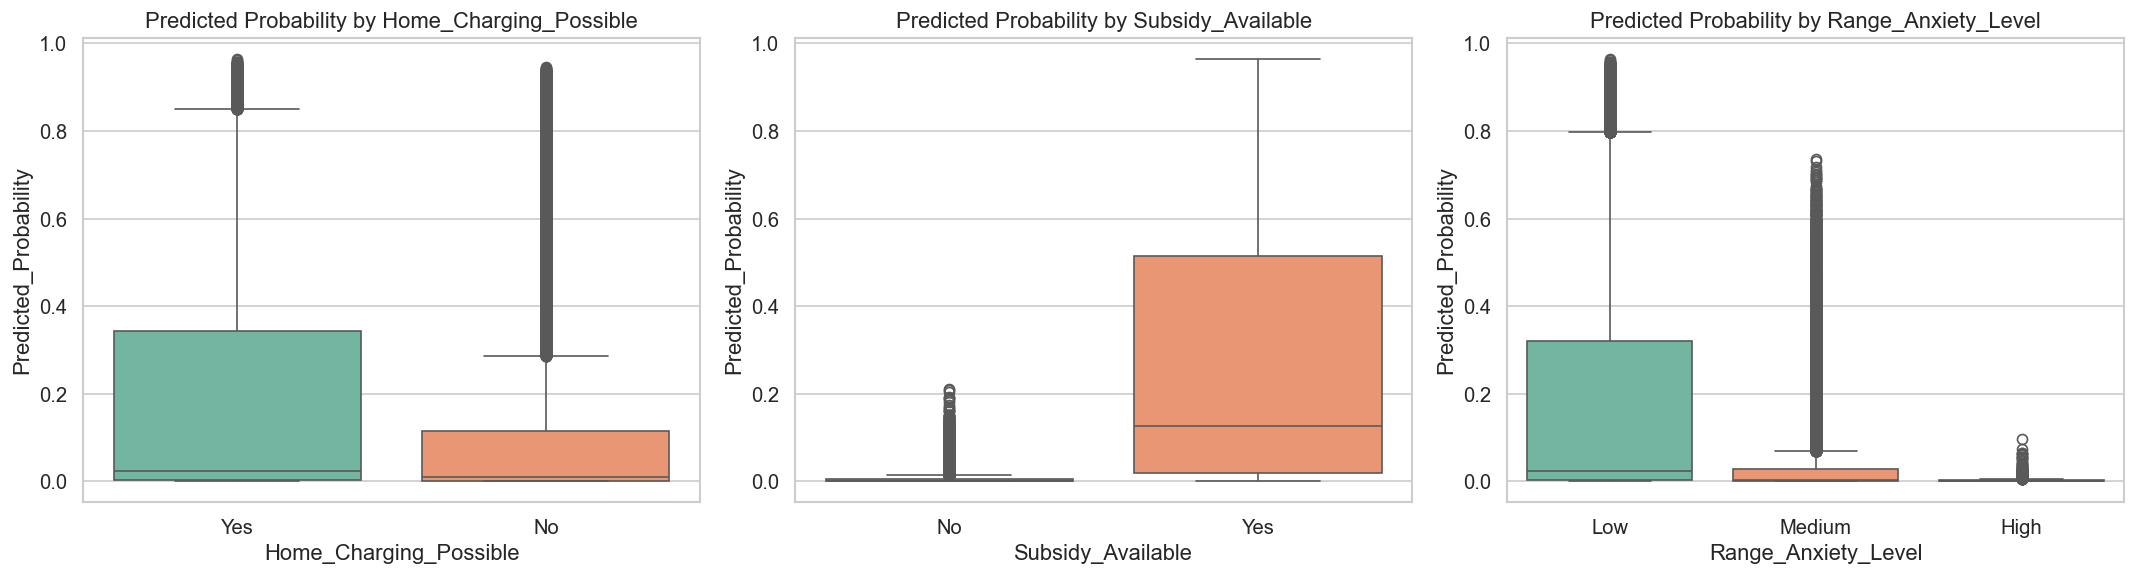

In [18]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['Home_Charging_Possible', 'Subsidy_Available', 'Range_Anxiety_Level']):
    sns.boxplot(data=test_analysis, x=col, y='Predicted_Probability',
                ax=axes[i], palette='Set2')
    axes[i].set_title(f'Predicted Probability by {col}')

plt.tight_layout()
plt.show()

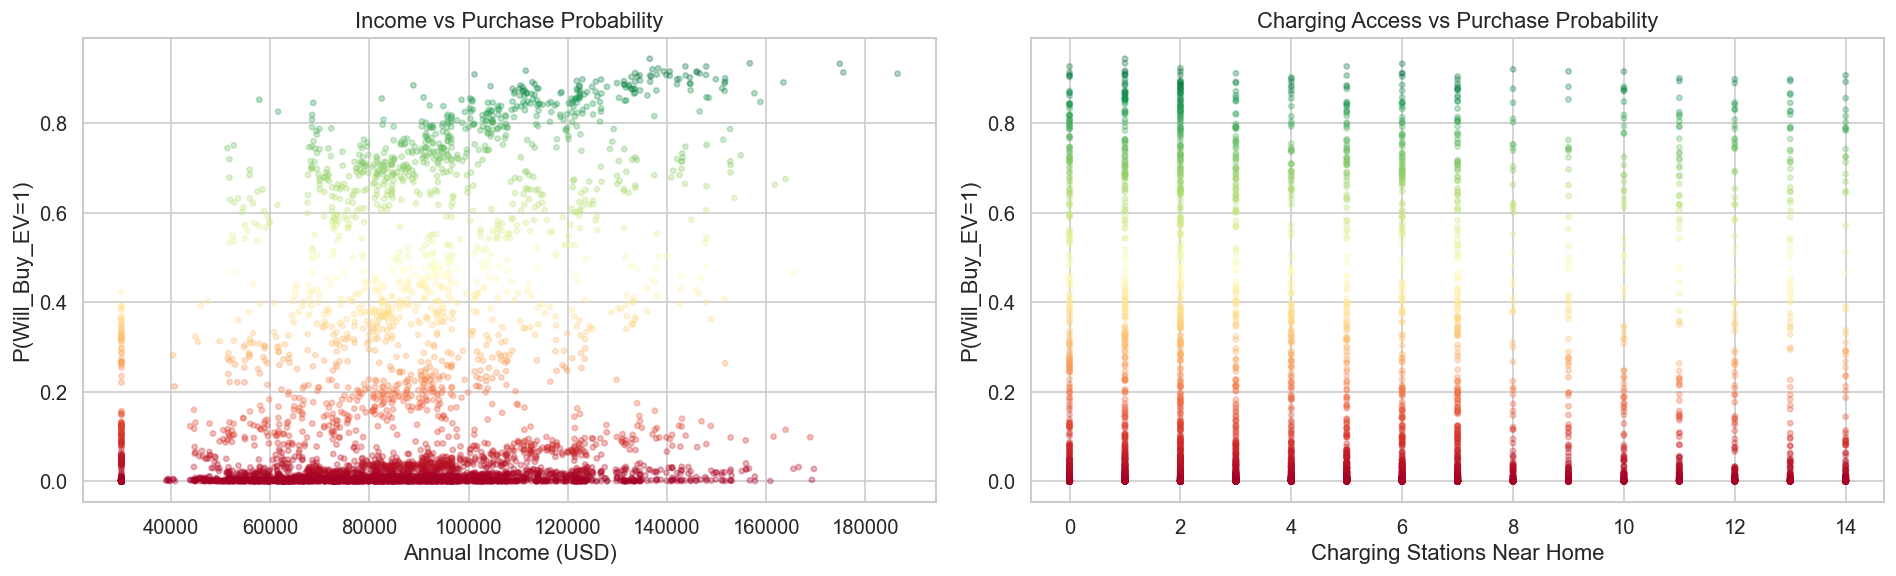

In [19]:

sample_vis = test_analysis.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(sample_vis['Annual_Income_USD'], sample_vis['Predicted_Probability'],
                alpha=0.3, s=10, c=sample_vis['Predicted_Probability'], cmap='RdYlGn')
axes[0].set_xlabel('Annual Income (USD)')
axes[0].set_ylabel('P(Will_Buy_EV=1)')
axes[0].set_title('Income vs Purchase Probability')

axes[1].scatter(sample_vis['Charging_Stations_Near_Home'], sample_vis['Predicted_Probability'],
                alpha=0.3, s=10, c=sample_vis['Predicted_Probability'], cmap='RdYlGn')
axes[1].set_xlabel('Charging Stations Near Home')
axes[1].set_ylabel('P(Will_Buy_EV=1)')
axes[1].set_title('Charging Access vs Purchase Probability')

plt.tight_layout()
plt.show()

---
## Single-Row Prediction Demo


In [20]:

new_person = pd.DataFrame([{
    'Age': 35,
    'Annual_Income_USD': 95000.0,
    'Daily_Commute_km': 25.0,
    'Number_of_Cars_Owned': 1,
    'Charging_Stations_Near_Home': 8,
    'Charging_Stations_Near_Work': 12,
    'Environmental_Concern_Level': 4.0,
    'Gender': 'Female',
    'City_Type': 'Urban',
    'Current_Car_Type': 'Sedan',
    'Home_Charging_Possible': 'Yes',
    'Subsidy_Available': 'Yes',
    'Range_Anxiety_Level': 'Low'
}])

print('New person data:')
new_person

New person data:


,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level
0,35,95000.0,25.0,1,8,12,4.0,Female,Urban,Sedan,Yes,Yes,Low


In [21]:

new_person_transformed = transform_data(new_person, encoding_info, feature_cols)

if needs_scaling:
    new_person_input = scaler.transform(new_person_transformed)
else:
    new_person_input = new_person_transformed

prob = best_model.predict_proba(new_person_input)[0, 1]
pred_class = 'Yes' if prob >= 0.5 else 'No'

print(f'\nPrediction for new person:')
print(f'   Probability of buying EV: {prob:.4f} ({prob*100:.1f}%)')
print(f'   Predicted class: {pred_class}')


Prediction for new person:
   Probability of buying EV: 0.4221 (42.2%)
   Predicted class: No


In [22]:

new_person_2 = pd.DataFrame([{
    'Age': 60,
    'Annual_Income_USD': 40000.0,
    'Daily_Commute_km': 10.0,
    'Number_of_Cars_Owned': 2,
    'Charging_Stations_Near_Home': 1,
    'Charging_Stations_Near_Work': 0,
    'Environmental_Concern_Level': 1.0,
    'Gender': 'Male',
    'City_Type': 'Rural',
    'Current_Car_Type': 'Truck',
    'Home_Charging_Possible': 'No',
    'Subsidy_Available': 'No',
    'Range_Anxiety_Level': 'High'
}])

new_person_2_transformed = transform_data(new_person_2, encoding_info, feature_cols)
if needs_scaling:
    new_person_2_input = scaler.transform(new_person_2_transformed)
else:
    new_person_2_input = new_person_2_transformed

prob2 = best_model.predict_proba(new_person_2_input)[0, 1]
pred_class2 = 'Yes' if prob2 >= 0.5 else 'No'

print(f'\nPrediction for person 2 (low affinity profile):')
print(f'   Probability of buying EV: {prob2:.4f} ({prob2*100:.1f}%)')
print(f'   Predicted class: {pred_class2}')


Prediction for person 2 (low affinity profile):
   Probability of buying EV: 0.0000 (0.0%)
   Predicted class: No


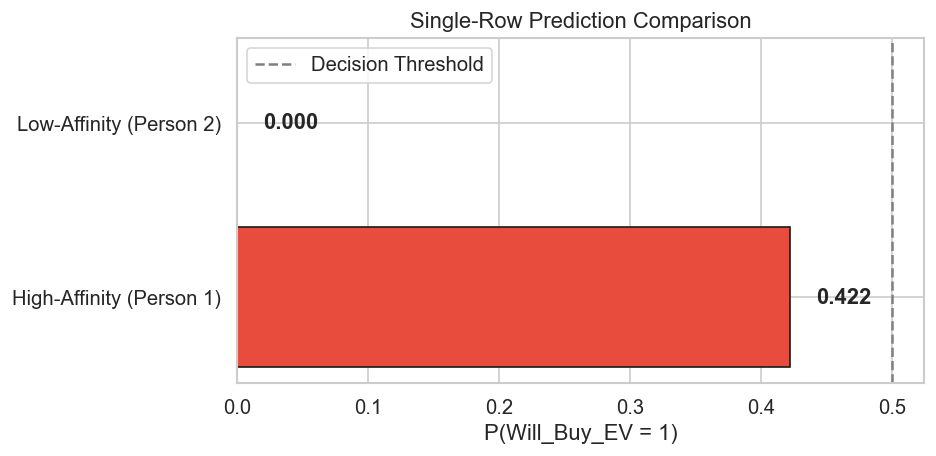


Prediction notebook complete!


In [23]:

comparison = pd.DataFrame({
    'Profile': ['High-Affinity (Person 1)', 'Low-Affinity (Person 2)'],
    'Probability': [prob, prob2],
    'Prediction': [pred_class, pred_class2]
})

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#2ecc71' if p >= 0.5 else '#e74c3c' for p in comparison['Probability']]
bars = ax.barh(comparison['Profile'], comparison['Probability'], color=colors, edgecolor='k')
ax.axvline(0.5, color='gray', linestyle='--', label='Decision Threshold')
ax.set_xlabel('P(Will_Buy_EV = 1)')
ax.set_title('Single-Row Prediction Comparison')
ax.legend()

for bar, val in zip(bars, comparison['Probability']):
    ax.text(val + 0.02, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print('\nPrediction notebook complete!')